# 07. Notification policy proposals

**Goal**: Combine the results of 03-06 into rules for **when, how often, and to whom** walking notifications are sent, and use this data to evaluate what each rule gains and loses compared with the current policy.

**Questions**
1. What evidence from 03-06 can guide the policy, and how strong is it?
2. For each rule, how many notifications are removed, and how many steps are lost in exchange?
3. Is the number of notifications related to total daily steps?
4. What should be proposed, and how should it be tested?

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

pd.set_option("display.max_columns", None)

# This notebook lives in notebooks/, so the project folder is one level up.
PROJECT_DIR = Path("..")
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

BLUE = "#2a78d6"
GREY = "#9a9893"
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "axes.axisbelow": True,
})

decision_points = pd.read_csv(PROCESSED_DIR / "decision_points.csv")
users = pd.read_csv(RAW_DIR / "users.csv")
jbsteps = pd.read_csv(RAW_DIR / "jbsteps.csv")
print(decision_points.shape, users.shape, jbsteps.shape)

(8274, 31) (37, 117) (237865, 10)


### 0.1. Analysis samples
Build the same walking vs no-notification sample as in 04-06 (`walk_vs_none`) and attach prior fitness app or tracker use (`fitness_tech`) from 06. Anti-sedentary notifications showed no step effect in 03 and 04, so the policies are about walking notifications.

In [2]:
fitness_tech = users[["user.index", "fitapp", "fittracker"]].rename(columns={"user.index": "user_id"})
fitness_tech["fitness_tech"] = np.where(
    (fitness_tech["fitapp"] == "yes") | (fitness_tech["fittracker"] == "yes"), "used before", "new"
)

sample = decision_points[(decision_points["available"] == 1) & (decision_points["travel_day"] == 0)]
sample = sample.merge(fitness_tech[["user_id", "fitness_tech"]], on="user_id", how="left")
sample["active"] = (sample["send_type"] == "active").astype(int)

walk_vs_none = sample[sample["send_type"].isin(["active", "none"])].reset_index(drop=True)
print(f"Walking vs none: {len(walk_vs_none)} rows, {walk_vs_none['user_id'].nunique()} participants")

Walking vs none: 4675 rows, 37 participants


## 1. Evidence from 03-06
| Finding | Source | Strength |
| --- | --- | --- |
| The effect is large early (about +59% on day 0) and reaches 0 around day 29. | 03 sec 2 (replicates the paper) | Strong: significant decline (p = 0.005) |
| The effect comes from walking notifications (+23.5%), not anti-sedentary ones (+2.9%). | 03 sec 4 | Strong |
| Large effects at lunch (+75.6%) and on weekdays (+31.5%); little in the morning commute (-1.1%) and on weekends (+9.0%). | 04 sec 2,4 | Moderate: same in both versions, but difference tests p > 0.1 |
| Engagement diverges from the effect and stays at 74% → 68% after the effect fades. | 05 sec 3, 4 | Strong: same pattern across situations, types, time, and people |
| Little effect for people who have used fitness apps or trackers (+2.9% vs +39.0% for newcomers). | 06 sec 4 | Weak: 14 people, difference p = 0.087 |

## 2. Candidate policies

Build rules from the evidence in section 1. Every rule uses only information known **before** sending (time slot, day, time since starting, sign-up survey), never the response (section 5 of 05, data leakage).

| Rule | May send walking notifications at | Based on |
| --- | --- | --- |
| A. Current | every available point | baseline |
| B. No morning commute | slots 2-5 | 04 |
| C. Weekdays only | weekdays | 04 |
| D. Weekdays, no morning commute | slots 2-5 on weekdays | 04 |
| E. First 4 weeks only | study weeks 1-4 | 03, 05 |
| F. New users only | people new to fitness apps or trackers | 06 |
| G. D within the first 4 weeks | D's points in weeks 1-4 | 03, 04 |
| H. Weekday lunch only | slot 2 on weekdays | 04 (the narrowest rule) |

Points where `send` is True are a rule's **send times**; False marks its **no-send times**.

In [3]:
is_weekday = walk_vs_none["is_weekend"] == 0
not_morning = walk_vs_none["slot"] != 1
first_4_weeks = walk_vs_none["study_week"] < 4          # study_week starts at 0
new_user = walk_vs_none["fitness_tech"] == "new"

policies = {
    "B. No morning commute": not_morning,
    "C. Weekdays only": is_weekday,
    "D. Weekdays, no morning commute": is_weekday & not_morning,
    "E. First 4 weeks only": first_4_weeks,
    "F. New users only": new_user,
    "G. D within the first 4 weeks": is_weekday & not_morning & first_4_weeks,
    "H. Weekday lunch only": is_weekday & (walk_vs_none["slot"] == 2),
}

## 3. Evaluating the policies

### 3-1. How a rule is compared with the current policy

A rule and the current policy (A) behave differently **only at the rule's no-send times**.

| | Current (A) | Rule |
| --- | --- | --- |
| Send times | walking notification with probability 0.3 | the same |
| No-send times | walking notification with probability 0.3 | none |

Therefore:
- **What a rule gives up** is the effect of the notifications that the current policy sends at the rule's no-send times (`effect_no_send`); "the effect at no-send times" always means this below. If it is close to 0, those notifications were not increasing steps, so nothing is lost by skipping them. **This is the key number for judging a policy.**
- **What a rule gains** is fewer notifications (`removed_pct`). Notifications were randomized with the same probability at every point, so the share of no-send times is the share of notifications removed.
- **Change in overall effect** (`change_pct`): how much 30-minute steps change on average across all available points, computed as share of no-send times × probability a walking notification was sent then (0.3) × effect of notifications at no-send times.
- **The effect at send times** (`effect_send`) is the same under both policies. It shows whether the rule picks the right moments, not that it makes people walk more than now.

This works because notifications were randomized at every available point (section 1 of 02) and the rules use only information known before sending, so comparing sent with not sent within the no-send times is still a randomized comparison.

### 3-2. Functions
`fit_gee` is the same as in 03-06. `policy_effect` computes the values of section 3.1 for one rule.

In [4]:
OUTCOME = "log_steps_post30_zero"
PRE = "log_steps_pre30_zero"
WALK_PROB = 0.3          # design: notification with probability 0.6, half of them walking notifications


def fit_gee(formula, data):
    model = smf.gee(
        formula,
        groups="user_id",                         # standard errors per participant
        data=data,
        cov_struct=sm.cov_struct.Independence(),
        missing="drop",                           # skip rows with a missing value in the formula
    )
    result = model.fit(cov_type="bias_reduced")   # small-sample correction
    ci = result.conf_int()
    table = pd.DataFrame({
        "estimate": result.params,
        "std_err": result.bse,
        "p_value": result.pvalues,
        "ci_low": ci[0],
        "ci_high": ci[1],
    })
    return table.round(3)


def to_pct(value):
    return round((np.exp(value) - 1) * 100, 1)


def policy_effect(name, send, outcome=OUTCOME, pre=PRE):
    removed = 1 - send.mean()
    at_no_send = fit_gee(f"{outcome} ~ {pre} + active", walk_vs_none[~send]).loc["active"]
    at_send = fit_gee(f"{outcome} ~ {pre} + active", walk_vs_none[send]).loc["active"]
    return {
        "policy": name,
        "removed_pct": round(removed * 100, 1),
        # what the rule gives up: notifications at its no-send times
        "effect_no_send": to_pct(at_no_send["estimate"]),
        "no_send_ci_low": to_pct(at_no_send["ci_low"]),
        "no_send_ci_high": to_pct(at_no_send["ci_high"]),
        "p_no_send": at_no_send["p_value"],
        # change in 30-minute steps across all available points
        "change_pct": to_pct(-removed * WALK_PROB * at_no_send["estimate"]),
        "change_ci_low": to_pct(-removed * WALK_PROB * at_no_send["ci_high"]),
        "change_ci_high": to_pct(-removed * WALK_PROB * at_no_send["ci_low"]),
        # same under both policies: how well the rule picks the right moments
        "effect_send": to_pct(at_send["estimate"]),
    }

### 3-3. Results

In [5]:
evaluation = pd.DataFrame([policy_effect(name, send) for name, send in policies.items()]).set_index("policy")
evaluation

,removed_pct,effect_no_send,no_send_ci_low,no_send_ci_high,p_no_send,change_pct,change_ci_low,change_ci_high,effect_send
policy,,,,,,,,,
B. No morning commute,22.5,-1.1,-27.5,34.7,0.943,0.1,-2.0,2.2,33.9
C. Weekdays only,28.0,9.0,-18.6,45.9,0.563,-0.7,-3.1,1.7,31.5
"D. Weekdays, no morning commute",44.1,5.3,-14.4,29.6,0.626,-0.7,-3.4,2.1,43.2
E. First 4 weeks only,39.2,-8.0,-28.5,18.5,0.519,1.0,-2.0,4.0,50.5
F. New users only,39.0,2.9,-22.5,36.9,0.840,-0.3,-3.6,3.0,39.0
G. D within the first 4 weeks,65.9,5.2,-12.5,26.5,0.586,-1.0,-4.5,2.7,70.7
H. Weekday lunch only,86.4,15.3,-4.8,39.4,0.145,-3.6,-8.2,1.3,98.4


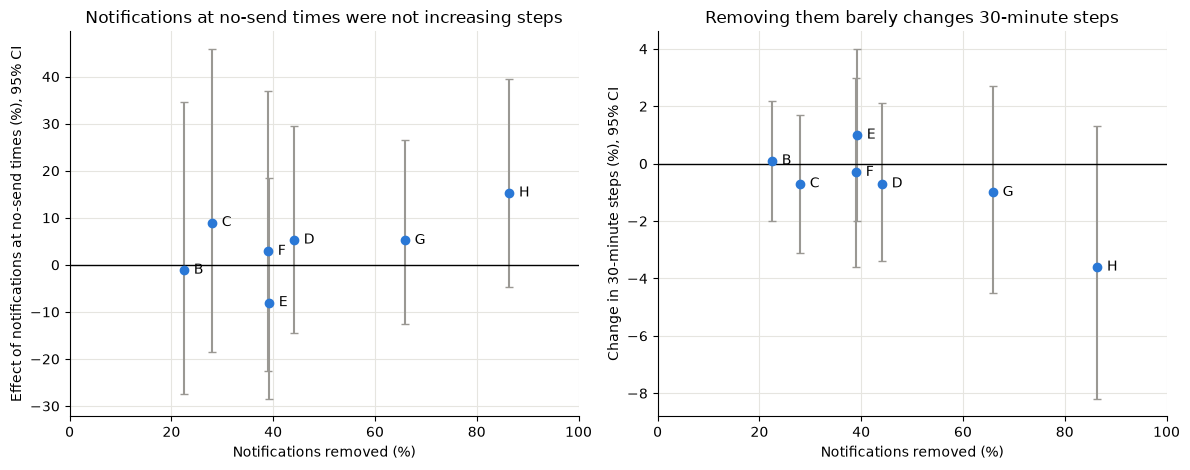

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Left: what each rule gives up
error = [evaluation["effect_no_send"] - evaluation["no_send_ci_low"],
         evaluation["no_send_ci_high"] - evaluation["effect_no_send"]]
axes[0].errorbar(evaluation["removed_pct"], evaluation["effect_no_send"], yerr=error,
                 fmt="o", color=BLUE, ecolor=GREY, capsize=3)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set(title="Notifications at no-send times were not increasing steps",
            xlabel="Notifications removed (%)",
            ylabel="Effect of notifications at no-send times (%), 95% CI")

# Right: change in 30-minute steps across all available points
error = [evaluation["change_pct"] - evaluation["change_ci_low"],
         evaluation["change_ci_high"] - evaluation["change_pct"]]
axes[1].errorbar(evaluation["removed_pct"], evaluation["change_pct"], yerr=error,
                 fmt="o", color=BLUE, ecolor=GREY, capsize=3)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set(title="Removing them barely changes 30-minute steps",
            xlabel="Notifications removed (%)",
            ylabel="Change in 30-minute steps (%), 95% CI")

for ax, col in zip(axes, ["effect_no_send", "change_pct"]):
    for name, row in evaluation.iterrows():
        ax.annotate(name.split(".")[0], (row["removed_pct"], row[col]),
                    xytext=(7, 0), textcoords="offset points", va="center", fontsize=10)   # letter only
    ax.set_xlim(0, 100)

plt.tight_layout()
plt.show()

- **For B-G, the effect of notifications at no-send times is indistinguishable from 0** (p > 0.5): the notifications they skip were not increasing steps.
- **D (weekdays, no morning commute)** removes 44.1% of notifications; those at its no-send times had a +5.3% effect (p = 0.626), and 30-minute steps change by only -0.7% overall (95% CI -3.4% to +2.1%).
- **E (first 4 weeks only)** and **F (new users only)** also remove about 39% with overall changes near 0 (+1.0% and -0.3%).
- **H (weekday lunch only)** removes 86.4%, but its no-send times may still carry a +15.3% effect (p = 0.145); the overall change is -3.6% (95% CI -8.2% to +1.3%), the largest loss. **It also skips moments that work.**
- The effect at send times (`effect_send`) grows as rules narrow (D +43.2%, H +98.4%). This means the rules pick moments that work, not that they make people walk more than now (section 3.1).

## 4. Sensitivity analysis
Recompute section 3 with missing steps left out.

In [7]:
left_out = pd.DataFrame(
    [policy_effect(name, send, outcome="log_steps_post30", pre="log_steps_pre30") for name, send in policies.items()]
).set_index("policy")

pd.DataFrame({
    "removed_pct": evaluation["removed_pct"],
    "effect_no_send_missing_0": evaluation["effect_no_send"],
    "effect_no_send_left_out": left_out["effect_no_send"],
    "p_no_send_left_out": left_out["p_no_send"],
    "change_missing_0": evaluation["change_pct"],
    "change_left_out": left_out["change_pct"],
})

,removed_pct,effect_no_send_missing_0,effect_no_send_left_out,p_no_send_left_out,change_missing_0,change_left_out
policy,,,,,,
B. No morning commute,22.5,-1.1,-5.9,0.717,0.1,0.4
C. Weekdays only,28.0,9.0,9.2,0.597,-0.7,-0.7
"D. Weekdays, no morning commute",44.1,5.3,6.2,0.613,-0.7,-0.8
E. First 4 weeks only,39.2,-8.0,-3.8,0.754,1.0,0.5
F. New users only,39.0,2.9,7.1,0.662,-0.3,-0.8
G. D within the first 4 weeks,65.9,5.2,7.1,0.458,-1.0,-1.4
H. Weekday lunch only,86.4,15.3,14.7,0.178,-3.6,-3.5


- With missing values left out, B-G still show effects at no-send times indistinguishable from 0 (p > 0.4) and overall changes near 0 (-1.4% to +0.5%). H again shows the largest effect at no-send times (+14.7%) and loss (-3.5%).

## 5. Daily steps
Sections 3 and 4 used 30-minute steps. What happens to **daily** steps when notifications are reduced? Notifications were randomized at each point, so **the number received in a day is also random**. Comparing daily steps on days with more or fewer notifications estimates the effect of the daily count.

- Daily steps: sum the minute-level steps in `jbsteps.csv` by person and date.
- Use non-travel days with all 5 decision points.
- The number of available points is not random, so it goes into the model.

In [14]:
# 하루 걸음 수 
jbsteps["date"] = pd.to_datetime(jbsteps["steps.utime.local"]).dt.normalize()
daily_steps = (
    jbsteps.groupby(["user.index", "date"])["steps"].sum()
    .rename("daily_steps").reset_index()
    .rename(columns={"user.index": "user_id"})
)

days = decision_points[decision_points["travel_day"] == 0].copy()
days["date"] = pd.to_datetime(days["decision_time_local"]).dt.normalize()
days["walking"] = (days["send_type"] == "active").astype(int)
days["sedentary"] = (days["send_type"] == "sedentary").astype(int)

per_day = days.groupby(["user_id", "date"]).agg(
    points=("decision_id", "size"),
    available=("available", "sum"),
    walking=("walking", "sum"),
    sedentary=("sedentary", "sum"),
).reset_index()
per_day = per_day.merge(daily_steps, on=["user_id", "date"], how="inner")
per_day = per_day[per_day["points"] == 5]
per_day["log_daily_steps"] = np.log(per_day["daily_steps"] + 0.5)

print(f"Person-days analyzed: {len(per_day)} ({per_day['user_id'].nunique()} participants, about {len(per_day) / per_day['user_id'].nunique():.0f} days each)")

Person-days analyzed: 1479 (37 participants, about 40 days each)


- Each row is **one person's day**. People differ a lot in how much they walk, so days with more and fewer notifications are compared **within each person**, then averaged over participants. This needs enough people with days at each count. First, for each number of walking notifications per day, count the participants who have at least one such day and the number of such days per person.

In [15]:
days_per_person = per_day.groupby(["user_id", "walking"]).size().unstack(fill_value=0)

pd.DataFrame({
    "participants_with_such_days": (days_per_person > 0).sum(),
    "median_days_per_person": days_per_person.median(),
}).rename_axis("walking_notifications_per_day")

,participants_with_such_days,median_days_per_person
walking_notifications_per_day,,
0,37,9.0
1,37,15.0
2,37,10.0
3,35,4.0
4,19,1.0
5,1,0.0


- Counts 0-2: all 37 people, 9-15 days each. Count 3: 35 people, 4 days each.
- Count 4: only 19 people, mostly a single day each; count 5: a single day of one person. Kept separate, their averages would rest on one or two days, and each column would compare different people.
- -> Group them as **3+**: 36 people then have such days, so nearly the same people are compared in every column. The model below still uses the original counts (0-5).

Now compute each person's average daily steps for each count and average over participants.

In [16]:
per_day["walking_notifications_per_day"] = per_day["walking"].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3+"})
person_means = per_day.groupby(["user_id", "walking_notifications_per_day"])["daily_steps"].mean().unstack()

pd.DataFrame({
    "participants": person_means.notna().sum(),
    "mean_daily_steps": person_means.mean().round(0),
})

,participants,mean_daily_steps
walking_notifications_per_day,,
0,37,8127.0
1,37,8454.0
2,37,8477.0
3+,36,8654.0


In [17]:
daily_table = fit_gee("log_daily_steps ~ available + walking + sedentary", per_day)
daily_table["effect_pct"] = [to_pct(v) for v in daily_table["estimate"]]
daily_table.loc[["walking", "sedentary"]]

,estimate,std_err,p_value,ci_low,ci_high,effect_pct
walking,0.024,0.022,0.270,-0.019,0.067,2.4
sedentary,0.008,0.030,0.801,-0.052,0.067,0.8


- Per person, days with no walking notification average 8,127 steps and days with 3 or more average 8,654: slightly more on busier days, but a small difference (about 500 steps).
- In the model, each walking notification adds +2.4% daily steps (p = 0.270), not clear; anti-sedentary notifications add +0.8% (p = 0.801).
- The effect in the 30 minutes after a notification (03) may be swamped by variation over the rest of the day, or offset by walking less later.
- -> There is no evidence that fewer notifications would visibly reduce daily steps, consistent with section 3.
- Caution: only 34 days had 4-5 walking notifications, and unworn time is recorded as 0 steps, so wear time is mixed in.

## 6. Proposals

| Proposal | What | Evidence | Expected |
| --- | --- | --- | --- |
| **1. Timing** | Send walking notifications only on weekdays from lunch to evening; skip the morning commute and weekends (rule D). | 04; 07, sections 3 and 5 | 44% fewer notifications; 30-minute steps change -0.7% (not distinguishable from 0) |
| **2. Frequency** | Send as now for the first 4 weeks, then reduce frequency or change content and format (rule E). | 03, 05; 07, section 3 | 39% fewer notifications; change +1.0% |
| **3. Audience** | Ask at sign-up whether the user has used a fitness app or tracker, and test other approaches (goal setting, progress feedback) for those who have (rule F). | 06; 07, section 3 | A hypothesis to test |
| **4. Measurement** | Measure success as the step difference against a random **holdout** of withheld notifications, not by engagement. | 05 | Keeps showing which notifications stop working |

**What the proposals claim**
Rule D does not make people **walk more**; it **removes notifications that were not working while keeping steps about the same**. Fewer notifications can mean less fatigue and less risk of muting or deleting the app, so it is a user-experience improvement.

**Why rule D first**
- It removes the most notifications (44.1%) among rules whose notifications at no-send times show no effect. G removes more (65.9%) but adds the first-4-weeks condition, fitting the same data more closely.
- It uses only the two most stable findings (weekdays and skipping the morning commute), which held in both versions in section 4 of 04.
- It keeps several chances a day (lunch, afternoon, evening commute, after dinner); H skips moments that work (section 3).
- It uses only time slot and day, so it can be applied right away.

## 7. Validation plan and limitations

**What these estimates do and do not mean**
- They mean: under **this study's conditions** (5 points a day, notifications with probability 0.6), the notifications at a rule's no-send times were not increasing 30-minute steps. Thanks to randomization, this is a causal estimate.
- They do not mean: using a rule for weeks changes how notifications are experienced (e.g. less fatigue), so the effect of the remaining notifications may differ from these estimates.
- The rules were built by looking at low-effect situations in the same data, so some effects at no-send times may be small by chance, especially for combined rules such as G and H.

**How to test**
1. Randomly split new users into the current policy (A) and rule D.
2. In both groups, randomly withhold notifications at some points (a holdout), as in this study.
3. **Primary**: daily steps and 30-minute steps after a notification (sent vs not sent). **Secondary**: snooze rate, app dropout, and the notification effect late in the study. Engagement is not a primary metric.

**Limitations**
- 37 participants from a highly educated, university-centered group in the US in 2015-2016; results may not apply directly to general app users (see 06).
- Most differences between situations and between users were not confirmed by difference tests (section 3 of 04, section 4 of 06).
- The link between daily steps and notification count was not clear (section 5), and what happens when notifications are reduced for weeks (fatigue, dropout) cannot be answered with this data.